In [1]:
#https://www.huduser.gov/portal/sites/default/files/xls/2007-2025-PIT-Counts-by-CoC.xlsb
#https://www.huduser.gov/portal/sites/default/files/xls/2007-2025-HIC-Counts-by-CoC.xlsx

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import io
import requests
from google.colab import drive
import warnings



In [3]:
# Data source https://www.huduser.gov/portal/sites/default/files/xls/2007-2025-PIT-Counts-by-CoC.xlsb

In [4]:
!pip install pyxlsb -q          # -q = quiet, hides the install messages

import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

folder = '/content/drive/MyDrive/'

# sheet_name=None loads every tab into a dictionary: {tab name: table}
pit_sheets = pd.read_excel(folder + '2007-2025-PIT-Counts-by-CoC.xlsb',
                           sheet_name=None, engine='pyxlsb')

print(list(pit_sheets.keys()))

Mounted at /content/drive
['2025', '2024', '2023', '2022', '2021', '2020', '2019', '2018', '2017', '2016', '2015', 'Table_categories', '2014', '2013', '2012', '2011', '2010', '2009', '2008', '2007', 'CoC Mergers', 'CoCs, States, DDs', 'field list, all years', 'Generate_Table', 'PIT_Counts_Table_Template', 'PIT_Counts_Table', 'Generate_Chart', 'Chart_categories', 'PIT_Counts_Chart', 'PIT_Counts_Chart_Template']


In [5]:
# Tab names that are all digits ('2024') are years. Everything else is notes/tools.
year_tabs = [name for name in pit_sheets if name.isdigit()]
print(year_tabs)

['2025', '2024', '2023', '2022', '2021', '2020', '2019', '2018', '2017', '2016', '2015', '2014', '2013', '2012', '2011', '2010', '2009', '2008', '2007']


In [6]:
pit_2024 = pit_sheets['2024']

print(pit_2024.shape)        # (rows, columns): about 390 regions, about 1,000 columns
pit_2024.iloc[:5, :8]        # first 5 rows, first 8 columns only, so it's readable

(390, 1018)


,CoC Number,CoC Name,Count Types,Overall Homeless,Overall Homeless - Under 18,Overall Homeless - Age 18 to 24,Overall Homeless - Age 25 to 34,Overall Homeless - Age 35 to 44
0,AK-500,Anchorage CoC,Sheltered and Unsheltered Count,1709.0,241.0,169.0,305.0,407.0
1,AK-501,Alaska Balance of State CoC,Sheltered and Unsheltered Count,977.0,202.0,59.0,190.0,217.0
2,AL-500,"Birmingham/Jefferson, St. Clair, Shelby Counti...",Sheltered and Unsheltered Count,911.0,89.0,50.0,151.0,174.0
3,AL-501,Mobile City & County/Baldwin County CoC,Sheltered and Unsheltered Count,675.0,155.0,20.0,96.0,113.0
4,AL-502,Florence/Northwest Alabama CoC,Sheltered and Unsheltered Count,210.0,50.0,13.0,47.0,42.0


In [7]:
cols = ['CoC Number', 'CoC Name', 'Overall Homeless',
        'Sheltered Total Homeless', 'Unsheltered Homeless']

# Only keep names that actually exist in this tab (protects against typos)
cols = [c for c in cols if c in pit_2024.columns]
print(cols)

small = pit_2024[cols]
small.head()

['CoC Number', 'CoC Name', 'Overall Homeless', 'Sheltered Total Homeless', 'Unsheltered Homeless']


,CoC Number,CoC Name,Overall Homeless,Sheltered Total Homeless,Unsheltered Homeless
0,AK-500,Anchorage CoC,1709.0,1363.0,346.0
1,AK-501,Alaska Balance of State CoC,977.0,844.0,133.0
2,AL-500,"Birmingham/Jefferson, St. Clair, Shelby Counti...",911.0,516.0,395.0
3,AL-501,Mobile City & County/Baldwin County CoC,675.0,324.0,351.0
4,AL-502,Florence/Northwest Alabama CoC,210.0,156.0,54.0


In [8]:
small[small['CoC Number'] == 'NM-500']

,CoC Number,CoC Name,Overall Homeless,Sheltered Total Homeless,Unsheltered Homeless
249,NM-500,Albuquerque CoC,2740.0,1509.0,1231.0


In [9]:
small.tail()

,CoC Number,CoC Name,Overall Homeless,Sheltered Total Homeless,Unsheltered Homeless
385,NaN,Total,771480.0,497256.0,274224.0
386,NaN,NaN,NaN,NaN,NaN
387,a MO-604 covers territory in both Missouri and...,NaN,NaN,NaN,NaN
388,* File does not contain the imputed race or ra...,NaN,NaN,NaN,NaN
389,"** Beginning in 2024, all variables for ""Non-H...",NaN,NaN,NaN,NaN


In [10]:
# Keep only real CoC codes: 2 letters, dash, 3 digits (e.g. NM-500)
# na=False treats blank CoC Numbers as "no match"
is_real_coc = small['CoC Number'].astype(str).str.match(r'^[A-Z]{2}-\d{3}$', na=False)

small_clean = small[is_real_coc]
print(small.shape, '->', small_clean.shape)   # should drop about 5 rows
small_clean.tail()

(390, 5) -> (384, 5)


,CoC Number,CoC Name,Overall Homeless,Sheltered Total Homeless,Unsheltered Homeless
380,WV-500,Wheeling/Weirton Area CoC,129.0,87.0,42.0
381,WV-501,"Huntington/Cabell, Wayne Counties CoC",278.0,208.0,70.0
382,WV-503,"Charleston/Kanawha, Putnam, Boone, Clay Counti...",335.0,193.0,142.0
383,WV-508,West Virginia Balance of State CoC,1037.0,503.0,534.0
384,WY-500,Wyoming Statewide CoC,501.0,412.0,89.0


In [11]:
pit_2024['Count Types'].value_counts()

,count
Count Types,
Sheltered and Unsheltered Count,363
Sheltered-Only Count,22


In [12]:
for yr in ['2025', '2024', '2022', '2021']:
    print(yr)
    print(pit_sheets[yr]['Count Types'].value_counts(), '\n')

2025
Count Types
Sheltered and Unsheltered Count    357
Sheltered-Only Count                29
Name: count, dtype: int64 

2024
Count Types
Sheltered and Unsheltered Count    363
Sheltered-Only Count                22
Name: count, dtype: int64 

2022
Count Types
Sheltered and Unsheltered Count    371
Sheltered-Only Count                16
Name: count, dtype: int64 

2021
Count Types
Sheltered-Only Count                       162
Sheltered and full unsheltered count       149
Sheltered and partial unsheltered count     76
Name: count, dtype: int64 



In [13]:
needed = ['CoC Number', 'CoC Name', 'Count Types', 'Overall Homeless',
          'Sheltered Total Homeless', 'Unsheltered Homeless']

for yr in year_tabs:
    missing = [c for c in needed if c not in pit_sheets[yr].columns]
    print(yr, 'missing:', missing)

2025 missing: []
2024 missing: []
2023 missing: []
2022 missing: []
2021 missing: []
2020 missing: []
2019 missing: []
2018 missing: []
2017 missing: []
2016 missing: []
2015 missing: []
2014 missing: []
2013 missing: []
2012 missing: []
2011 missing: []
2010 missing: []
2009 missing: []
2008 missing: ['Count Types']
2007 missing: ['Count Types']


## Data decision: drop "Sheltered-Only Count" rows
Our target is the number of UNSHELTERED people. HUD only requires CoCs to count
people sleeping outside every other year, and in 2021 many skipped it because of COVID.
When a CoC did a sheltered-only count, its unsheltered number is 0 or blank because
nobody went out and counted, NOT because nobody was outside. Keeping those rows would
teach the model that some regions have zero unsheltered people when we don't actually know.

In [14]:
# ---------------------------------------------------------------
# Stack every year of PIT into one long table: one row = one CoC in one year
# ---------------------------------------------------------------

needed = ['CoC Number', 'CoC Name', 'Count Types', 'Overall Homeless',
          'Sheltered Total Homeless', 'Unsheltered Homeless']

pieces = []
for yr in year_tabs:
    df = pit_sheets[yr]

    # 2007 and 2008 have no 'Count Types' column, so keep whatever columns exist
    df = df[[c for c in needed if c in df.columns]].copy()
    df['year'] = int(yr)
    pieces.append(df)

pit_long = pd.concat(pieces, ignore_index=True)
print('Stacked:', pit_long.shape)

# ---------------------------------------------------------------
# Remove the national "Total" row and the footnote rows at the bottom of each tab.
# Real CoC codes start with 2 letters, a dash, 3 digits (e.g. NM-500).
# No '$' at the end, so codes with a footnote letter like 'MO-604a' are kept.
# ---------------------------------------------------------------
is_real_coc = pit_long['CoC Number'].astype(str).str.match(r'^[A-Z]{2}-\d{3}', na=False)
pit_long = pit_long[is_real_coc].copy()
pit_long['CoC Number'] = pit_long['CoC Number'].str[:6]   # 'MO-604a' -> 'MO-604'
print('After removing Total/footnotes:', pit_long.shape)

# ---------------------------------------------------------------
# WHY WE DROP "Sheltered-Only Count" ROWS:
# Our target is UNSHELTERED people. In a sheltered-only year, the CoC did not
# go out and count people sleeping outside. Its unsheltered number is 0 or blank
# because nobody counted, NOT because nobody was there. Keeping these rows would
# give the model fake zeros. HUD only requires the street count every other year,
# and in 2021 many CoCs skipped it for COVID, so this mostly removes even years and 2021.
#
# NOTE: 2007-2008 have no 'Count Types' column (NaN), so they are KEPT.
# NOTE: 2021 also has "Sheltered and partial unsheltered count" rows. These are KEPT for now,
#       but their unsheltered numbers are incomplete. Revisit this.
# ---------------------------------------------------------------
before = len(pit_long)
pit_long = pit_long[pit_long['Count Types'] != 'Sheltered-Only Count'].copy()
print(f'Dropped {before - len(pit_long)} sheltered-only rows ->', pit_long.shape)

Stacked: (7491, 7)
After removing Total/footnotes: (7431, 7)
Dropped 633 sheltered-only rows -> (6798, 7)


In [15]:
# How many regions are left in each year?
pit_long['year'].value_counts().sort_index()

,count
year,
2007,394
2008,390
2009,391
2010,348
2011,392
2012,268
2013,392
2014,305
2015,395


In [16]:
# Albuquerque's remaining years
pit_long[pit_long['CoC Number'] == 'NM-500'][['year', 'Count Types', 'Unsheltered Homeless']]

,year,Count Types,Unsheltered Homeless
249,2025,Sheltered and Unsheltered Count,1367.0
638,2024,Sheltered and Unsheltered Count,1231.0
1028,2023,Sheltered and Unsheltered Count,977.0
1419,2022,Sheltered and Unsheltered Count,163.0
1809,2021,Sheltered and full unsheltered count,413.0
2602,2019,Sheltered and Unsheltered Count,567.0
3400,2017,Sheltered and Unsheltered Count,384.0
4195,2015,Sheltered and Unsheltered Count,183.0
4983,2013,Sheltered and Unsheltered Count,144.0
5772,2011,Sheltered and Unsheltered Count,387.0


In [17]:
# Every Count Types label, across all years (dropna=False also shows the blanks)
pit_long['Count Types'].value_counts(dropna=False)

,count
Count Types,
Sheltered and Unsheltered Count,5678
NaN,784
Sheltered and full unsheltered count,149
No 2010 PIT Count,89
Sheltered and partial unsheltered count,76
Sheltered-Only Count*,22


In [18]:
# For each CoC, line up its 2007 and 2008 unsheltered numbers side by side
u07 = pit_long[pit_long['year'] == 2007].set_index('CoC Number')['Unsheltered Homeless']
u08 = pit_long[pit_long['year'] == 2008].set_index('CoC Number')['Unsheltered Homeless']

both = pd.concat([u07, u08], axis=1, keys=['2007', '2008']).dropna()
same = (both['2007'] == both['2008']).sum()
print(f'{same} of {len(both)} CoCs have the identical number in 2007 and 2008')

131 of 389 CoCs have the identical number in 2007 and 2008


In [19]:
# ---------------------------------------------------------------
# REMOVE ROWS THAT AREN'T REAL UNSHELTERED COUNTS
# ---------------------------------------------------------------

# 1. Sheltered-only, INCLUDING the 'Sheltered-Only Count*' version with an asterisk.
#    We match on PART of the text (.contains) instead of the exact text (!=),
#    because HUD adds footnote marks like * to some labels.
is_sheltered_only = pit_long['Count Types'].astype(str).str.contains('Sheltered-Only')

# 2. 'No 2010 PIT Count': HUD copied 2009's number forward. Not a new count.
is_no_count = pit_long['Count Types'].astype(str).str.startswith('No ')

# 3. 2008 rows that exactly match the same CoC's 2007 number.
#    131 of 389 CoCs matched exactly, far too many for coincidence,
#    so HUD copied 2007 forward for those. Keep 2007 (the real count), drop the 2008 copy.
#    (A few could be true coincidences, e.g. a small CoC with 0 both years. Accepted tradeoff.)
copied_cocs = both.index[both['2007'] == both['2008']]
is_2008_copy = (pit_long['year'] == 2008) & (pit_long['CoC Number'].isin(copied_cocs))

print('Sheltered-only (incl. *):', is_sheltered_only.sum())   # expect 22
print('No 2010 count:', is_no_count.sum())                    # expect 89
print('2008 copies of 2007:', is_2008_copy.sum())             # expect 131

# ~ means NOT, and | means OR: keep rows that are none of the three
before = len(pit_long)
pit_long = pit_long[~(is_sheltered_only | is_no_count | is_2008_copy)].copy()
print(f'Dropped {before - len(pit_long)} rows ->', pit_long.shape)   # expect about 6556 rows

Sheltered-only (incl. *): 22
No 2010 count: 89
2008 copies of 2007: 131
Dropped 242 rows -> (6556, 7)


In [20]:
# Should show only real count labels now (plus NaN for 2007-2008)
pit_long['Count Types'].value_counts(dropna=False)

,count
Count Types,
Sheltered and Unsheltered Count,5678
NaN,653
Sheltered and full unsheltered count,149
Sheltered and partial unsheltered count,76


### NOTE: NM-500 2022 unsheltered = 163, far below 2021 (413) and 2023 (977).
### Possibly a change in count method, not a real drop. Kept, but flagged in write-up.

In [21]:
pit_long.to_csv(folder + 'pit_clean.csv', index=False)
# Next session: pit_long = pd.read_csv(folder + 'pit_clean.csv')

In [22]:
# DATA SOURCE- https://www.huduser.gov/portal/sites/default/files/xls/2007-2025-HIC-Counts-by-CoC.xlsx

In [23]:
import warnings
# openpyxl warns about Excel print headers/footers. Harmless, so hide it.
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')

hic_sheets = pd.read_excel(folder + '2007-2025-HIC-Counts-by-CoC.xlsx',
                           sheet_name=None, engine='openpyxl')

hic_year_tabs = [name for name in hic_sheets if name.isdigit()]
print(hic_year_tabs)

['2025', '2024', '2023', '2022', '2021', '2020', '2019', '2018', '2017', '2016', '2015', '2014', '2013', '2012', '2011', '2010', '2009', '2008', '2007']


In [24]:
hic_2024 = hic_sheets['2024']
print(hic_2024.shape)
print(hic_2024.columns[:12].tolist())   # first 12 column names as pandas sees them
hic_2024.iloc[:3, :8]                    # first 3 rows, first 8 columns

(387, 77)
['Unnamed: 0', 'Total Beds (ES, TH, SH)', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11']


,Unnamed: 0,"Total Beds (ES, TH, SH)",Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7
0,CoC Number,"Total Year-Round Beds (ES, TH, SH)","Total Non-DV Year-Round Beds (ES, TH, SH)","Total HMIS Year-Round Beds (ES, TH, SH)",HMIS Participation Rate for Year-Round Beds (E...,Total Year-Round Beds (ES),Total Year-Round Beds (TH),Total Year-Round Beds (SH)
1,AK-500,921,854,669,0.7264,617,304,0
2,AK-501,1118,602,531,0.475,821,297,0


In [25]:
for word in ['Emergency', 'Transitional', 'Permanent Supportive', 'Safe Haven', 'Total']:
    print(word, '->', [c for c in hic_2024.columns if word in str(c)])

Emergency -> ['Emergency Shelter (ES)']
Transitional -> ['Transitional Housing (TH)']
Permanent Supportive -> ['Permanent Supportive Housing (PSH)']
Safe Haven -> ['Safe Haven (SH)']
Total -> ['Total Beds (ES, TH, SH)']


In [26]:
# 1. Every column name, numbered. repr() shows hidden spaces, e.g. 'CoC Number '
for i, c in enumerate(hic_2024.columns[:15]):
    print(i, repr(c))

0 'Unnamed: 0'
1 'Total Beds (ES, TH, SH)'
2 'Unnamed: 2'
3 'Unnamed: 3'
4 'Unnamed: 4'
5 'Unnamed: 5'
6 'Unnamed: 6'
7 'Unnamed: 7'
8 'Unnamed: 8'
9 'Unnamed: 9'
10 'Unnamed: 10'
11 'Unnamed: 11'
12 'Unnamed: 12'
13 'Unnamed: 13'
14 'Emergency Shelter (ES)'


In [27]:
# 2. The first 3 rows, first 6 columns
hic_2024.iloc[:3, :6]

,Unnamed: 0,"Total Beds (ES, TH, SH)",Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,CoC Number,"Total Year-Round Beds (ES, TH, SH)","Total Non-DV Year-Round Beds (ES, TH, SH)","Total HMIS Year-Round Beds (ES, TH, SH)",HMIS Participation Rate for Year-Round Beds (E...,Total Year-Round Beds (ES)
1,AK-500,921,854,669,0.7264,617
2,AK-501,1118,602,531,0.475,821


In [28]:
# 3. Find which column holds 'NM-500', wherever it is
for c in hic_2024.columns:
    if hic_2024[c].astype(str).str.contains('NM-500', na=False).any():
        print('NM-500 found in column:', repr(c))

NM-500 found in column: 'Unnamed: 0'


In [29]:
hic_2024.tail()   # check for a Total row and footnotes, like PIT had

,Unnamed: 0,"Total Beds (ES, TH, SH)",Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Other Permanent Housing (OPH),Unnamed: 68,Unnamed: 69,Unnamed: 70,Unnamed: 71,Unnamed: 72,Unnamed: 73,Unnamed: 74,Unnamed: 75,Unnamed: 76
382,WV-501,220,198,185,0.8409,212,0,8,23,71,...,98,90,90,0.9184,4,8,90,0,0,2
383,WV-503,213,187,157,0.7371,198,15,0,17,56,...,0,0,0,.,0,0,0,0,0,0
384,WV-508,771,520,451,0.585,654,117,0,105,319,...,139,139,129,0.9281,27,78,61,0,8,0
385,WY-500,704,556,370,0.5256,480,224,0,58,180,...,0,0,0,.,0,0,0,0,0,0
386,Total,509710,463911,391588,0.7683,421973,85485,2252,80909,246630,...,136962,135898,85027,0.6208,27254,75135,61646,181,3681,3170


In [30]:
# header=1 means "use the SECOND row as column names" (Python counts from 0).
# The first row in HIC is section titles (merged cells), not real column names.
hic_sheets = pd.read_excel(folder + '2007-2025-HIC-Counts-by-CoC.xlsx',
                           sheet_name=None, engine='openpyxl', header=1)

hic_2024 = hic_sheets['2024']
print(hic_2024.shape)
hic_2024.iloc[:3, :6]

(386, 77)


,CoC Number,"Total Year-Round Beds (ES, TH, SH)","Total Non-DV Year-Round Beds (ES, TH, SH)","Total HMIS Year-Round Beds (ES, TH, SH)","HMIS Participation Rate for Year-Round Beds (ES, TH, SH)",Total Year-Round Beds (ES)
0,AK-500,921,854,669,0.7264,617
1,AK-501,1118,602,531,0.4750,821
2,AL-500,563,478,478,0.8490,473


In [31]:
hic_2024[hic_2024['CoC Number'] == 'NM-500']

,CoC Number,"Total Year-Round Beds (ES, TH, SH)","Total Non-DV Year-Round Beds (ES, TH, SH)","Total HMIS Year-Round Beds (ES, TH, SH)","HMIS Participation Rate for Year-Round Beds (ES, TH, SH)",Total Year-Round Beds (ES),Total Year-Round Beds (TH),Total Year-Round Beds (SH),"Total Units for Households with Children (ES, TH, SH)","Total Beds for Households with Children (ES, TH, SH)",...,Total Year-Round Beds (OPH),Total Non-DV Year-Round Beds (OPH),Total HMIS Year-Round Beds (OPH),HMIS Participation Rate for Year-Round Beds (OPH),Total Units for Households with Children (OPH),Total Beds for Households with Children (OPH),Total Beds for Households without Children (OPH),Total Beds for Households with only Children (OPH),Dedicated Veteran Beds (OPH),Dedicated Youth Beds (OPH)
249,NM-500,1908,1821,1271,0.6661,1504,404,0,197,708,...,148,148,50,0.3378,40,94,53,1,0,1


In [32]:
bed_cols = ['Total Year-Round Beds (ES)',
            'Total Year-Round Beds (TH)',
            'Total Year-Round Beds (PSH)']

# Which exist in 2024? Anything printed as missing needs its real name found.
print('found:  ', [c for c in bed_cols if c in hic_2024.columns])
print('missing:', [c for c in bed_cols if c not in hic_2024.columns])

hic_2024.loc[hic_2024['CoC Number'] == 'NM-500', ['CoC Number'] + [c for c in bed_cols if c in hic_2024.columns]]

found:   ['Total Year-Round Beds (ES)', 'Total Year-Round Beds (TH)', 'Total Year-Round Beds (PSH)']
missing: []


,CoC Number,Total Year-Round Beds (ES),Total Year-Round Beds (TH),Total Year-Round Beds (PSH)
249,NM-500,1504,404,2587


In [33]:
needed_hic = ['CoC Number'] + bed_cols

for yr in hic_year_tabs:
    missing = [c for c in needed_hic if c not in hic_sheets[yr].columns]
    print(yr, 'missing:', missing)

2025 missing: ['CoC Number', 'Total Year-Round Beds (ES)', 'Total Year-Round Beds (TH)', 'Total Year-Round Beds (PSH)']
2024 missing: []
2023 missing: []
2022 missing: []
2021 missing: []
2020 missing: []
2019 missing: []
2018 missing: []
2017 missing: []
2016 missing: []
2015 missing: []
2014 missing: []
2013 missing: ['Total Year-Round Beds (ES)', 'Total Year-Round Beds (TH)', 'Total Year-Round Beds (PSH)']
2012 missing: ['CoC Number', 'Total Year-Round Beds (ES)', 'Total Year-Round Beds (TH)', 'Total Year-Round Beds (PSH)']
2011 missing: ['CoC Number', 'Total Year-Round Beds (ES)', 'Total Year-Round Beds (TH)', 'Total Year-Round Beds (PSH)']
2010 missing: ['CoC Number', 'Total Year-Round Beds (ES)', 'Total Year-Round Beds (TH)', 'Total Year-Round Beds (PSH)']
2009 missing: ['CoC Number', 'Total Year-Round Beds (ES)', 'Total Year-Round Beds (TH)', 'Total Year-Round Beds (PSH)']
2008 missing: ['CoC Number', 'Total Year-Round Beds (ES)', 'Total Year-Round Beds (TH)', 'Total Year-Round 

In [34]:
# header=None means: don't treat ANY row as column names, give me everything as data.
# We'll find the real header row ourselves, one year at a time.
hic_raw = pd.read_excel(folder + '2007-2025-HIC-Counts-by-CoC.xlsx',
                        sheet_name=None, engine='openpyxl', header=None)

def fix_header(df, max_rows=10):
    """Find the first row (in the top 10) whose first cell starts with 'CoC',
    use that row as the column names, and keep only the rows below it."""
    for i in range(max_rows):
        first_cell = str(df.iloc[i, 0]).strip()
        if first_cell.startswith('CoC'):
            new = df.iloc[i + 1:].copy()
            new.columns = df.iloc[i].astype(str).str.strip()   # .strip() removes hidden spaces
            return new.reset_index(drop=True), i
    return None, None

hic_fixed = {}
for yr in hic_year_tabs:
    table, row = fix_header(hic_raw[yr])
    hic_fixed[yr] = table
    print(yr, '-> header on row', row, '| first column name:',
          None if table is None else repr(table.columns[0]))

2025 -> header on row 0 | first column name: 'CoC Number'
2024 -> header on row 1 | first column name: 'CoC Number'
2023 -> header on row 1 | first column name: 'CoC Number'
2022 -> header on row 1 | first column name: 'CoC Number'
2021 -> header on row 1 | first column name: 'CoC Number'
2020 -> header on row 1 | first column name: 'CoC Number'
2019 -> header on row 1 | first column name: 'CoC Number'
2018 -> header on row 1 | first column name: 'CoC Number'
2017 -> header on row 1 | first column name: 'CoC Number'
2016 -> header on row 1 | first column name: 'CoC Number'
2015 -> header on row 1 | first column name: 'CoC Number'
2014 -> header on row 1 | first column name: 'CoC Number'
2013 -> header on row 1 | first column name: 'CoC Number'
2012 -> header on row 1 | first column name: 'CoC'
2011 -> header on row 1 | first column name: 'CoC'
2010 -> header on row 1 | first column name: 'CoC'
2009 -> header on row 1 | first column name: 'CoC'
2008 -> header on row 1 | first column nam

In [35]:
for yr in ['2025', '2013', '2012', '2007']:
    if hic_fixed[yr] is not None:
        beds = [c for c in hic_fixed[yr].columns if 'Bed' in c and
                any(t in c for t in ['ES', 'TH', 'PSH', 'Emergency', 'Transitional', 'Permanent'])]
        print(yr, beds, '\n')

2025 ['Total Year-Round Beds (ES, TH, SH)', 'Total Non-DV Year-Round Beds (ES, TH, SH)', 'Total HMIS Year-Round Beds (ES, TH, SH)', 'HMIS Participation Rate for Year-Round Beds (ES, TH, SH)', 'Total Year-Round Beds (ES)', 'Total Year-Round Beds (TH)', 'Total Beds for Households with Children (ES, TH, SH)', 'Total Beds for Households without Children (ES, TH, SH)', 'Total Beds for Households with only Children (ES, TH, SH)', 'Dedicated Veteran Beds (ES, TH, SH)', 'Dedicated Youth Beds (ES, TH, SH)', 'Total Year-Round Beds (ES)', 'Total Non-DV Year-Round Beds (ES)', 'Total HMIS Year-Round Beds (ES)', 'HMIS Participation Rate for Year-Round Beds (ES)', 'Total Seasonal Beds (ES)', 'Total Overflow Beds (ES)', 'Total Beds for Households with Children (ES)', 'Total Beds for Households without Children (ES)', 'Total Beds for Households with only Children (ES)', 'Dedicated Veteran Beds (ES)', 'Dedicated Youth Beds (ES)', 'Total Year-Round Beds (TH)', 'Total Non-DV Year-Round Beds (TH)', 'Total 

In [36]:
h25 = hic_fixed['2025']
dup_names = h25.columns[h25.columns.duplicated()].unique().tolist()
print('Duplicated names in 2025:', dup_names)

# Are the two copies identical? .iloc[:, 0] and [:, 1] = first and second copy
for name in ['Total Year-Round Beds (ES)', 'Total Year-Round Beds (TH)']:
    copies = h25.loc[:, h25.columns == name]
    print(name, '-> copies identical:', copies.iloc[:, 0].equals(copies.iloc[:, 1]))

Duplicated names in 2025: ['Total Year-Round Beds (ES)', 'Total Year-Round Beds (TH)', 'Total Year-Round Beds (SH)']
Total Year-Round Beds (ES) -> copies identical: True
Total Year-Round Beds (TH) -> copies identical: True


In [37]:
# ---------------------------------------------------------------
# RENAME MAP: HUD renamed columns over the years.
# Old name (left) -> the 2014-2025 name we use everywhere (right).
# All are YEAR-ROUND beds (seasonal and overflow excluded) in every year.
# ---------------------------------------------------------------
rename_map = {
    'CoC':                       'CoC Number',                   # 2007-2012
    'Total Year-Round ES Beds':  'Total Year-Round Beds (ES)',   # 2007-2013
    'Total Year-Round TH Beds':  'Total Year-Round Beds (TH)',
    'Total Year-Round PSH Beds': 'Total Year-Round Beds (PSH)',
}

needed_hic = ['CoC Number',
              'Total Year-Round Beds (ES)',
              'Total Year-Round Beds (TH)',
              'Total Year-Round Beds (PSH)']

pieces = []
for yr in hic_year_tabs:
    df = hic_fixed[yr].copy()

    # 2025 has some column names twice (same numbers, checked above). Keep the first copy.
    df = df.loc[:, ~df.columns.duplicated()]

    df = df.rename(columns=rename_map)

    missing = [c for c in needed_hic if c not in df.columns]
    if missing:
        print(yr, 'STILL MISSING:', missing)   # should never print
        continue

    df = df[needed_hic].copy()
    df['year'] = int(yr)
    pieces.append(df)

hic_long = pd.concat(pieces, ignore_index=True)
print('Stacked:', hic_long.shape)

# ---------------------------------------------------------------
# Remove the national 'Total' row and footnotes (same rule as PIT)
# ---------------------------------------------------------------
is_real_coc = hic_long['CoC Number'].astype(str).str.match(r'^[A-Z]{2}-\d{3}', na=False)
hic_long = hic_long[is_real_coc].copy()
hic_long['CoC Number'] = hic_long['CoC Number'].str[:6]
print('After removing Total/footnotes:', hic_long.shape)

# ---------------------------------------------------------------
# Make the bed columns numbers.
# Because we read with header=None, pandas stored everything as text.
# errors='coerce' turns anything that isn't a number (like '.') into NaN.
# ---------------------------------------------------------------
bed_cols = needed_hic[1:]
for c in bed_cols:
    hic_long[c] = pd.to_numeric(hic_long[c], errors='coerce')

# Shorter names make the modeling code easier to read
hic_long = hic_long.rename(columns={
    'Total Year-Round Beds (ES)':  'beds_es',
    'Total Year-Round Beds (TH)':  'beds_th',
    'Total Year-Round Beds (PSH)': 'beds_psh',
})
hic_long.head()

Stacked: (7839, 5)
After removing Total/footnotes: (7818, 5)


,CoC Number,beds_es,beds_th,beds_psh,year
0,AK-500,859,265,818,2025
1,AK-501,726,270,450,2025
2,AL-500,422,45,1388,2025
3,AL-501,268,203,237,2025
4,AL-502,103,66,0,2025


In [38]:
print(hic_long.isna().sum())                         # any blanks after converting to numbers?
hic_long['year'].value_counts().sort_index()          # about 380-400 CoCs every year

CoC Number    0
beds_es       0
beds_th       0
beds_psh      0
year          0
dtype: int64


,count
year,
2007,461
2008,448
2009,447
2010,446
2011,432
2012,427
2013,420
2014,414
2015,406


In [39]:
hic_long.to_csv(folder + 'hic_clean.csv', index=False)

In [40]:
# Any CoC listed twice in the same year? A merge would duplicate those rows.
print('PIT duplicates:', pit_long.duplicated(['CoC Number', 'year']).sum())
print('HIC duplicates:', hic_long.duplicated(['CoC Number', 'year']).sum())

# Albuquerque's beds over time (you skipped this check earlier)
hic_long[hic_long['CoC Number'] == 'NM-500'].sort_values('year')

PIT duplicates: 0
HIC duplicates: 0


,CoC Number,beds_es,beds_th,beds_psh,year
7677,NM-500,329,551,582,2007
7219,NM-500,304,607,739,2008
6767,NM-500,327,657,830,2009
6321,NM-500,329,635,885,2010
5877,NM-500,367,531,943,2011
5447,NM-500,348,476,1004,2012
5026,NM-500,318,522,967,2013
4606,NM-500,369,529,1087,2014
4196,NM-500,378,520,1234,2015
3788,NM-500,367,512,1407,2016


In [41]:
# ---------------------------------------------------------------
# MERGE PIT (target) + HIC (beds) on region + year.
# how='inner' keeps only rows found in BOTH tables, because the model
# needs the beds AND the unsheltered count for every row.
# indicator=True would label each row's source, but with 'inner' they're all 'both',
# so we check the leftovers separately below.
# ---------------------------------------------------------------
df = pit_long.merge(hic_long, on=['CoC Number', 'year'], how='inner')
print('Merged:', df.shape)

# How much did we lose from each side?
print('PIT rows with no HIC match:', len(pit_long) - len(df))
print('HIC rows with no PIT match:', len(hic_long) - len(df))

Merged: (6545, 10)
PIT rows with no HIC match: 11
HIC rows with no PIT match: 1273


In [42]:
# PIT rows that found no beds in HIC
check = pit_long.merge(hic_long, on=['CoC Number', 'year'], how='left', indicator=True)
no_match = check[check['_merge'] == 'left_only']
print(len(no_match))
no_match[['CoC Number', 'CoC Name', 'year']].head(20)

11


,CoC Number,CoC Name,year
3189,CA-530,"Alpine, Inyo, Mono Counties CoC",2016
3549,CA-530,"Alpine, Inyo, Mono Counties CoC",2015
3985,LA-509,Louisiana Balance of State CoC,2014
4344,LA-509,Louisiana Balance of State CoC,2013
4663,LA-509,Louisiana Balance of State CoC,2012
5003,LA-509,Louisiana Balance of State CoC,2011
5555,CA-524,Yuba City & County/Sutter County CoC,2009
5644,KS-507,Kansas Balance of State CoC,2009
5654,LA-509,Louisiana Balance of State CoC,2009
5984,LA-509,Louisiana Balance of State CoC,2008


In [43]:
df[df['CoC Number'] == 'NM-500'][['year', 'Unsheltered Homeless',
                                  'beds_es', 'beds_th', 'beds_psh']].sort_values('year')

,year,Unsheltered Homeless,beds_es,beds_th,beds_psh
6409,2007,287.0,329,551,582
5757,2009,931.0,327,657,830
5109,2011,387.0,367,531,943
4451,2013,144.0,318,522,967
3757,2015,183.0,378,520,1234
3027,2017,384.0,372,310,1557
2285,2019,567.0,854,344,1382
1591,2021,413.0,825,535,1444
1324,2022,163.0,857,263,1422
949,2023,977.0,1337,432,2567


In [44]:
df.to_csv(folder + 'merged_clean.csv', index=False)

In [45]:
df['Unsheltered Homeless'].describe()

,Unsheltered Homeless
count,6545.000000
mean,501.394652
std,1968.130360
min,0.000000
25%,38.000000
50%,115.000000
75%,382.000000
max,52307.000000


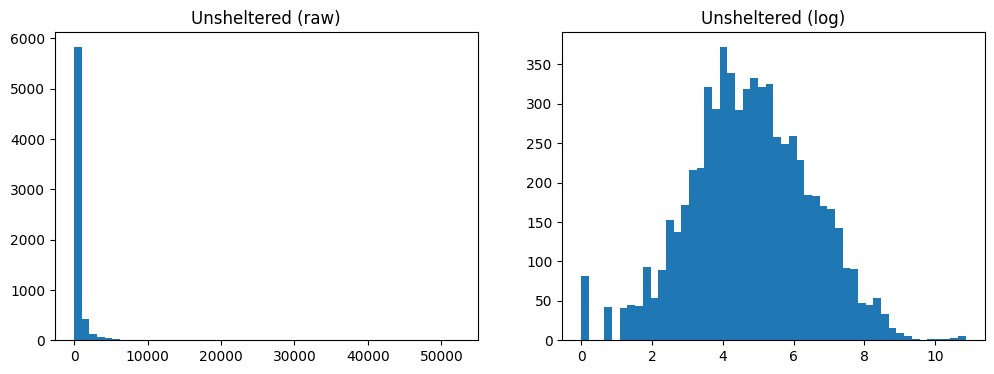

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: raw counts. Expect a tall bar near 0 and a long tail to the right.
axes[0].hist(df['Unsheltered Homeless'], bins=50)
axes[0].set_title('Unsheltered (raw)')

# Right: log scale. np.log1p(x) = log(x + 1), so regions with 0 don't break it.
axes[1].hist(np.log1p(df['Unsheltered Homeless']), bins=50)
axes[1].set_title('Unsheltered (log)')

plt.show()

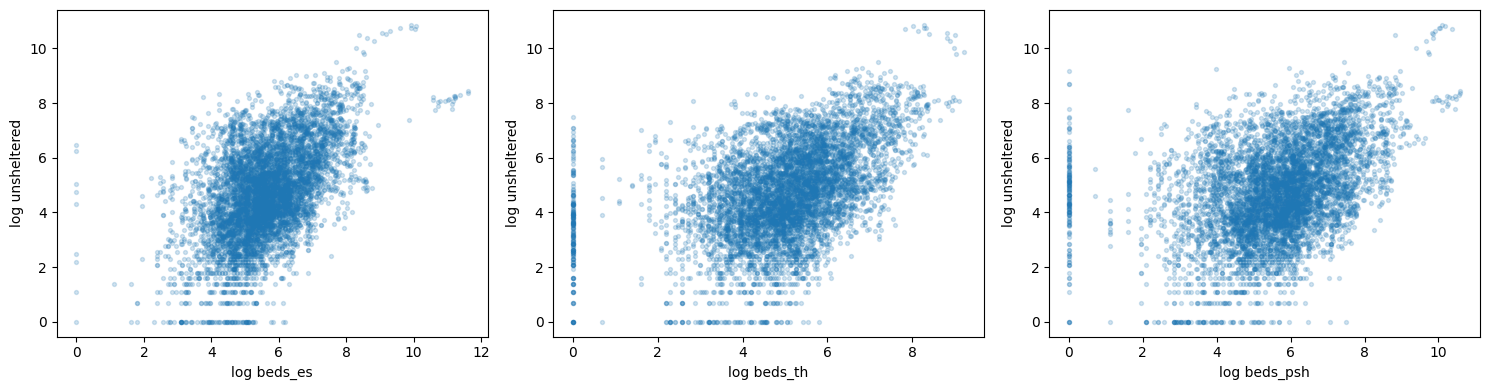

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ['beds_es', 'beds_th', 'beds_psh']):
    ax.scatter(np.log1p(df[col]), np.log1p(df['Unsheltered Homeless']), alpha=0.2, s=8)
    ax.set_xlabel(f'log {col}')
    ax.set_ylabel('log unsheltered')

plt.tight_layout()
plt.show()

In [48]:
df[['Unsheltered Homeless', 'beds_es', 'beds_th', 'beds_psh', 'year']].corr().round(2)

,Unsheltered Homeless,beds_es,beds_th,beds_psh,year
Unsheltered Homeless,1.00,0.25,0.49,0.52,0.01
beds_es,0.25,1.00,0.47,0.84,0.04
beds_th,0.49,0.47,1.00,0.65,-0.18
beds_psh,0.52,0.84,0.65,1.00,0.09
year,0.01,0.04,-0.18,0.09,1.00


In [49]:
# The 10 biggest regions by unsheltered count, latest year
latest = df[df['year'] == df['year'].max()]
latest.nlargest(10, 'Unsheltered Homeless')[['CoC Number', 'CoC Name',
        'Unsheltered Homeless', 'beds_es', 'beds_th', 'beds_psh']]

,CoC Number,CoC Name,Unsheltered Homeless,beds_es,beds_th,beds_psh
38,CA-600,Los Angeles City & County CoC,44415.0,22949,2475,31999
19,CA-500,San Jose/Santa Clara City & County CoC,7472.0,3017,431,5315
273,OR-501,"Portland, Gresham/Multnomah County CoC",6912.0,3350,817,6973
39,CA-601,San Diego City and County CoC,5714.0,3587,1328,7722
318,TX-607,Texas Balance of State (BoS) CoC,5351.0,4266,1336,1626
18,AZ-502,"Phoenix, Mesa/Maricopa County CoC",5207.0,4136,1432,5584
249,NY-600,New York City CoC,4673.0,110095,3165,39989
277,OR-505,Oregon Balance of State CoC,4171.0,1469,620,121
343,WA-501,Washington Balance of State CoC,3895.0,4683,1320,1990
26,CA-514,Fresno City & County/Madera County CoC,3042.0,1914,305,1284


In [50]:
# Spearman ranks the values first (1st, 2nd, 3rd...) and correlates the ranks.
# A giant region counts as "rank 1", not as "50,000", so it can't overpower the rest.
df[['Unsheltered Homeless', 'beds_es', 'beds_th', 'beds_psh', 'year']].corr(method='spearman').round(2)

,Unsheltered Homeless,beds_es,beds_th,beds_psh,year
Unsheltered Homeless,1.00,0.49,0.48,0.41,0.03
beds_es,0.49,1.00,0.66,0.73,0.11
beds_th,0.48,0.66,1.00,0.60,-0.27
beds_psh,0.41,0.73,0.60,1.00,0.18
year,0.03,0.11,-0.27,0.18,1.00


In [51]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

# ---------------------------------------------------------------
# WHY LOGS: unsheltered counts range from 0 to 52,307 (median 115).
# A few giant regions (LA, NYC) would dominate a model on raw counts.
# log1p(x) = log(x + 1), which squeezes big numbers together and handles zeros.
# ---------------------------------------------------------------
X = pd.DataFrame({
    'log_es':  np.log1p(df['beds_es']),
    'log_th':  np.log1p(df['beds_th']),
    'log_psh': np.log1p(df['beds_psh']),
    'year':    df['year'],
})
y = np.log1p(df['Unsheltered Homeless'])

# 80% to train, 20% to test. random_state=42 makes the split the same every run.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(5236, 4) (1309, 4)


In [52]:
lr = LinearRegression()
lr.fit(X_train, y_train)

pred_log = lr.predict(X_test)

# Convert predictions and actual values BACK to real people counts before scoring.
# expm1 undoes log1p. Then RMSE/MAE are in "people", which is easy to explain.
pred_people = np.expm1(pred_log)
true_people = np.expm1(y_test)

rmse = np.sqrt(mean_squared_error(true_people, pred_people))
mae  = mean_absolute_error(true_people, pred_people)
print(f'RMSE: {rmse:,.0f} people')
print(f'MAE:  {mae:,.0f} people')
print(f'R² (log scale): {lr.score(X_test, y_test):.2f}')

RMSE: 1,949 people
MAE:  439 people
R² (log scale): 0.32


In [53]:
pd.Series(lr.coef_, index=X.columns).round(3)

,0
log_es,0.515
log_th,0.336
log_psh,-0.019
year,0.019


In [54]:
nm = df['CoC Number'] == 'NM-500'
nm_pred = np.expm1(lr.predict(X[nm]))

pd.DataFrame({
    'year':      df.loc[nm, 'year'],
    'actual':    df.loc[nm, 'Unsheltered Homeless'],
    'predicted': nm_pred.round(0),
}).assign(gap=lambda t: t['actual'] - t['predicted']).sort_values('year')

,year,actual,predicted,gap
6409,2007,287.0,165.0,122.0
5757,2009,931.0,180.0,751.0
5109,2011,387.0,184.0,203.0
4451,2013,144.0,176.0,-32.0
3757,2015,183.0,199.0,-16.0
3027,2017,384.0,171.0,213.0
2285,2019,567.0,284.0,283.0
1591,2021,413.0,336.0,77.0
1324,2022,163.0,275.0,-112.0
949,2023,977.0,412.0,565.0


In [55]:
# Residual = actual minus predicted, on the LOG scale (before converting back).
# On the log scale the quirk doesn't apply, so regions can be compared fairly.
df['resid_log'] = y - lr.predict(X)

for yr in [2023, 2024, 2025]:
    d = df[df['year'] == yr]
    nm_resid = d.loc[d['CoC Number'] == 'NM-500', 'resid_log'].iloc[0]
    pct = (d['resid_log'] < nm_resid).mean() * 100
    print(f'{yr}: Albuquerque is above {pct:.0f}% of regions '
          f'(about {np.exp(nm_resid):.1f}x its predicted level)')

2023: Albuquerque is above 71% of regions (about 2.4x its predicted level)
2024: Albuquerque is above 71% of regions (about 2.8x its predicted level)
2025: Albuquerque is above 75% of regions (about 3.1x its predicted level)


In [56]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV

# ---------------------------------------------------------------
# WHY SCALE (lecture 210): ridge and lasso shrink coefficients toward zero.
# Year (~2007-2025) and log beds (~0-12) are on different scales, so without
# scaling the penalty would hit them unevenly. StandardScaler puts every input
# on the same scale (mean 0, std 1).
# RidgeCV / LassoCV try many penalty strengths (alphas) and pick the best by cross-validation.
# ---------------------------------------------------------------
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50)))
lasso = make_pipeline(StandardScaler(), LassoCV(alphas=np.logspace(-4, 0, 50), cv=5, random_state=42))

def score(model, name):
    model.fit(X_train, y_train)
    p = np.expm1(model.predict(X_test))
    t = np.expm1(y_test)
    print(f'{name:6s} RMSE {np.sqrt(mean_squared_error(t, p)):7,.0f} | '
          f'MAE {mean_absolute_error(t, p):5,.0f} | R² {model.score(X_test, y_test):.2f}')

score(lr, 'Linear')
score(ridge, 'Ridge')
score(lasso, 'Lasso')

Linear RMSE   1,949 | MAE   439 | R² 0.32
Ridge  RMSE   1,950 | MAE   439 | R² 0.32
Lasso  RMSE   1,953 | MAE   439 | R² 0.32


In [57]:
# Coefficients side by side. These are SCALED, so you can compare their sizes directly:
# a bigger number (positive or negative) means a stronger link.
pd.DataFrame({
    'ridge': ridge[-1].coef_,
    'lasso': lasso[-1].coef_,
}, index=X.columns).round(3)

,ridge,lasso
log_es,0.608,0.596
log_th,0.491,0.469
log_psh,-0.028,-0.000
year,0.102,0.083


In [58]:
# ---------------------------------------------------------------
# PEER COMPARISON: beds of each type PER HOMELESS PERSON,
# Albuquerque vs. regions of similar size in the same year.
# "Similar size" = overall homeless count within ±50% of Albuquerque's.
# ---------------------------------------------------------------
yr = 2025
d = df[df['year'] == yr].copy()
for b in ['beds_es', 'beds_th', 'beds_psh']:
    d[b + '_per_person'] = d[b] / d['Overall Homeless']

nm_total = d.loc[d['CoC Number'] == 'NM-500', 'Overall Homeless'].iloc[0]
peers = d[d['Overall Homeless'].between(nm_total * 0.5, nm_total * 1.5)]
print(f'{len(peers)} peer regions with {nm_total*0.5:,.0f}-{nm_total*1.5:,.0f} homeless people')

cols = ['beds_es_per_person', 'beds_th_per_person', 'beds_psh_per_person']
pd.DataFrame({
    'Albuquerque': d.loc[d['CoC Number'] == 'NM-500', cols].iloc[0],
    'Peer median': peers[cols].median(),
}).round(2)

75 peer regions with 1,480-4,440 homeless people


,Albuquerque,Peer median
beds_es_per_person,0.47,0.51
beds_th_per_person,0.16,0.14
beds_psh_per_person,0.86,0.59
